# Agentic RAG: Router–Retriever System with PDF and Web Search Tools

**Course-End Project** · Author: Alron Harry

This notebook builds a multi-agent **Agentic RAG** system with **CrewAI**:

| Agent | Role | Tools |
|---|---|---|
| **Router Agent** | Reads the question and decides the retrieval path: `pdf`, `web`, or `llm` (direct generation). It is given the paper's **table of contents, extracted from the PDF**, so it knows which questions the document can answer | none (pure reasoning) |
| **Retriever Agent** | Runs the chosen tool, then writes a grounded, cited answer | `PDFSearchTool` (crewai_tools) **or** `TavilySearchResults` (LangChain) — only the one the router picked |

Knowledge base: *Attention Is All You Need* (Vaswani et al., 2017) — `transformer_research_paper-dataset.pdf`.

**Notebook outline**
1. Setup & API keys
2. Trace logging (reasoning traceability)
3. Tools — PDF search & web search, plus the **table of contents** extracted for the Router
4. Agents — roles, goals, backstories
5. Tasks — routing task & retrieval task
6. Orchestrator — coordination flow (router → retriever, with fallback)
7. Demo — PDF, web, and direct-LLM questions, plus a routing check
8. Trace logs & visualisations
9. Why CrewAI? (framework justification)

**Where each project requirement is met**

| Requirement (problem statement) | Where |
|---|---|
| Roles and responsibilities for a Router and a Retriever agent | Section 4 (roles, goals, backstories, input → output table) |
| Workflow: accept a natural-language question → route → retrieve → grounded answer | Section 6, `AgenticRAG.ask()` |
| PDF search with `crewai_tools.PDFSearchTool` | Section 3 |
| Web search with `TavilySearchResults` | Section 3 |
| Optional direct-generation path (LLM without retrieval) | `llm` route, Sections 4 and 7.3 |
| Orchestration framework (CrewAI) and its justification | Sections 6 and 9 |
| Agent collaboration with clear input–output flows | Section 4 table and Section 6 diagram |
| Interaction logging for reasoning traceability | Section 2 (`TraceLogger`), Section 8 |
| Trace logs explaining each agent's contributions and interactions | Section 8.1 (`explain_run`, `print_run`) |
| Reasoning trace visualisations | Section 8.4 |
| Working demo with retrieval from both PDF and web sources | Section 7 |
| README: architecture, agent logic, coordination flow, challenges and trade-offs | `README.md` |

## 1. Setup

In [3]:
# Install dependencies (run once). Restart the kernel afterwards if prompted.
%pip install -q "crewai>=0.100" "crewai-tools>=0.33" langchain-community tavily-python pandas matplotlib pypdf

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.6/90.6 kB 7.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 54.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.9/238.9 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.6/853.6 kB 43.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 83.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.1/405.1 kB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3

In [4]:
import os, getpass



def load_key(name: str) -> str:
    """Colab Secrets first, then an existing environment variable, then a hidden prompt."""
    try:
        from google.colab import userdata
        value = userdata.get(name)          # raises if the secret is missing or notebook access is off
        if value:
            return value
    except ImportError:
        pass                                # not running in Colab
    except Exception as exc:
        print(f"Colab secret {name} not available ({type(exc).__name__}). "
              "Add it under Secrets (🔑) and turn on notebook access.")
    return os.environ.get(name) or getpass.getpass(f"Enter {name}: ")


for key in ["OPENAI_API_KEY", "TAVILY_API_KEY"]:
    os.environ[key] = load_key(key)        # CrewAI, LangChain and Tavily read keys from the environment

# CrewAI: no telemetry, and no interactive "view your execution traces?" prompt that pauses a run
os.environ["CREWAI_DISABLE_TELEMETRY"] = "true"
os.environ["CREWAI_TRACING_ENABLED"] = "false"

# Model used by both agents (small, cheap, good at following structured-output instructions)
MODEL_NAME = os.environ.get("RAG_MODEL", "gpt-4o-mini")

# Path to the knowledge-base PDF (keep it in the same folder as this notebook)
PDF_PATH = "transformer_research_paper-dataset.pdf"
assert os.path.exists(PDF_PATH), f"PDF not found at {PDF_PATH} — place it next to the notebook."

os.makedirs("logs", exist_ok=True)
print("Model:", MODEL_NAME, "| PDF:", PDF_PATH)

Model: gpt-4o-mini | PDF: transformer_research_paper-dataset.pdf


In [5]:
import json, time, uuid, logging, textwrap, warnings
from datetime import datetime
from typing import Literal, Optional, Type, Any, List, Dict

from pydantic import BaseModel, Field
from crewai import Agent, Task, Crew, Process, LLM
from crewai.tools import BaseTool
from crewai_tools import PDFSearchTool
from langchain_community.tools.tavily_search import TavilySearchResults

warnings.filterwarnings("ignore", category=DeprecationWarning)
llm = LLM(model=MODEL_NAME, temperature=0)

/tmp/ipykernel_558/1654725628.py:9: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


## 2. Trace logging

Every interaction is recorded as a structured event so each agent's contribution can be audited later:

* `run_start` / `run_end` — the user question and the final answer
* `agent_step` — each thought / action / tool call an agent makes (via CrewAI `step_callback`)
* `tool_call` / `tool_result` — exact query sent to a tool and what came back (logged inside the tool wrappers)
* `task_complete` — the output of each task (via CrewAI `task_callback`)
* `route_decision` / `fallback` — orchestration decisions

Events go to memory (for the visualisations), to `logs/trace.jsonl` (machine-readable), and to `logs/agentic_rag.log` (human-readable).

In [6]:
class TraceLogger:
    # Collects structured events for every run and mirrors them to disk.

    def __init__(self, jsonl_path="logs/trace.jsonl", log_path="logs/agentic_rag.log"):
        self.events: List[Dict[str, Any]] = []
        self.jsonl_path = jsonl_path
        self.run_id: Optional[str] = None
        self.logger = logging.getLogger("agentic_rag")
        self.logger.setLevel(logging.INFO)
        if not self.logger.handlers:
            fh = logging.FileHandler(log_path, encoding="utf-8")
            fh.setFormatter(logging.Formatter("%(asctime)s | %(message)s"))
            self.logger.addHandler(fh)

    def new_run(self, question: str) -> str:
        self.run_id = uuid.uuid4().hex[:8]
        self.log("Orchestrator", "run_start", question)
        return self.run_id

    def log(self, agent: str, event: str, content: Any, **extra):
        text = content if isinstance(content, str) else json.dumps(content, default=str)
        rec = {"run_id": self.run_id, "ts": time.time(),
               "time": datetime.now().strftime("%H:%M:%S.%f")[:-3],
               "agent": agent, "event": event, "content": text, **extra}
        self.events.append(rec)
        with open(self.jsonl_path, "a", encoding="utf-8") as f:
            f.write(json.dumps(rec, default=str) + "\n")
        self.logger.info(f"[{self.run_id}] {agent:<16} {event:<15} {text[:300]!r}")

    def print_run(self, run_id: str, width: int = 110):
        # Pretty-print the reasoning trace of one run.
        print(f"===== TRACE for run {run_id} =====")
        for e in [e for e in self.events if e["run_id"] == run_id]:
            body = textwrap.shorten(e["content"].replace("\n", " "), width=width, placeholder=" …")
            print(f"{e['time']}  {e['agent']:<16} {e['event']:<15} {body}")


tracer = TraceLogger()


def make_step_callback(agent_name: str):
    # CrewAI calls this after every agent step (AgentAction, ToolResult or AgentFinish).
    def _cb(step):
        kind = type(step).__name__
        payload = {}
        for attr in ("thought", "tool", "tool_input", "result", "output"):
            val = getattr(step, attr, None)
            if val:
                payload[attr] = str(val)[:1500]
        if not payload:
            payload["text"] = str(getattr(step, "text", step))[:1500]
        tracer.log(agent_name, "agent_step", payload, step_type=kind)
    return _cb


def task_callback(task_output):
    # CrewAI calls this when a task finishes.
    role = str(getattr(task_output, "agent", "unknown"))
    agent = {"Query Router": "Router Agent", "Retrieval Specialist": "Retriever Agent"}.get(role.strip(), role)
    tracer.log(agent, "task_complete", str(getattr(task_output, "raw", task_output))[:2000])

## 3. Tools

* **PDF search** — `crewai_tools.PDFSearchTool` chunks and embeds the paper into a vector store (OpenAI embeddings by default) and returns the most relevant passages for a query.
* **Web search** — LangChain's `TavilySearchResults` returns fresh results (title, URL, snippet) from the internet.

Both are wrapped in thin CrewAI `BaseTool` classes so that (a) every call and result is written to the trace log and (b) the web results are formatted with their URLs so the agent can cite them.

In [7]:
# --- Underlying tools -------------------------------------------------------
pdf_search = PDFSearchTool(pdf=PDF_PATH)            # builds the vector index on first use
tavily = TavilySearchResults(max_results=4)          # LangChain Tavily wrapper


class QueryInput(BaseModel):
    query: str = Field(..., description="A focused search query.")


class PaperSearchTool(BaseTool):
    name: str = "transformer_paper_search"
    description: str = (
        "Semantic search over the research paper 'Attention Is All You Need' (the Transformer paper). "
        "Returns the most relevant text passages. Use for questions about the Transformer architecture, "
        "attention, training setup, hyperparameters, and reported results."
    )
    args_schema: Type[BaseModel] = QueryInput

    def _run(self, query: str) -> str:
        tracer.log("PDFSearchTool", "tool_call", {"query": query})
        result = pdf_search.run(query=query)
        tracer.log("PDFSearchTool", "tool_result", str(result)[:3000])
        return str(result)


class WebSearchTool(BaseTool):
    name: str = "web_search"
    description: str = (
        "Searches the live web with Tavily. Returns titles, URLs and snippets. Use for recent events, "
        "current facts, or anything not covered by the Transformer paper."
    )
    args_schema: Type[BaseModel] = QueryInput

    def _run(self, query: str) -> str:
        tracer.log("TavilySearch", "tool_call", {"query": query})
        try:
            results = tavily.invoke({"query": query})
        except Exception as exc:                       # network / quota errors shouldn't crash the run
            tracer.log("TavilySearch", "tool_error", str(exc))
            return f"Web search failed: {exc}"
        if isinstance(results, str):
            formatted = results
        else:
            formatted = "\n\n".join(
                f"[{i}] {r.get('title', '')}\nURL: {r.get('url', '')}\n{r.get('content', '')}"
                for i, r in enumerate(results, 1)
            )
        tracer.log("TavilySearch", "tool_result", formatted[:3000])
        return formatted


paper_tool = PaperSearchTool()
web_tool = WebSearchTool()
TOOLS = {"pdf": paper_tool, "web": web_tool}

In [8]:
# Quick smoke test of both tools (also warms up the PDF vector index)
tracer.run_id = "smoke"
print(paper_tool._run("number of attention heads")[:600], "\n---")
print(web_tool._run("Transformer architecture latest developments")[:600])

INFO:agentic_rag:[smoke] PDFSearchTool    tool_call       '{"query": "number of attention heads"}'
INFO:agentic_rag:[smoke] PDFSearchTool    tool_result     'Relevant Content:\n\n\n\n\nPage 4:\n\nScaled Dot-Product Attention\n\nMulti-Head Attention\n\nFigure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several\n\nattention layers running in parallel.\n\nof the values, where the weight assigned to each value is computed by a compatibi'
INFO:agentic_rag:[smoke] TavilySearch     tool_call       '{"query": "Transformer architecture latest developments"}'


Relevant Content:




Page 4:

Scaled Dot-Product Attention

Multi-Head Attention

Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several

attention layers running in parallel.

of the values, where the weight assigned to each value is computed by a compatibility function of the

query with the corresponding key.

3.2.1

Scaled Dot-Product Attention

We call our particular attention "Scaled Dot-Product Attention" (Figure 2). The input consists of

queries and keys of dimension dk, and values of dimension dv. We compute the dot products of the

query wit 
---


INFO:agentic_rag:[smoke] TavilySearch     tool_result     '[1] The Evolution of Transformer Architecture: From 2017 to 2024 | by arghya mukherjee | Medium\nURL: https://medium.com/@arghya05/the-evolution-of-transformer-architecture-from-2017-to-2024-5a967488e63b\nThis design was simple yet effective, enabling unprecedented parallelization and scalability. How'


[1] The Evolution of Transformer Architecture: From 2017 to 2024 | by arghya mukherjee | Medium
URL: https://medium.com/@arghya05/the-evolution-of-transformer-architecture-from-2017-to-2024-5a967488e63b
This design was simple yet effective, enabling unprecedented parallelization and scalability. However, as model sizes grew and use cases expanded, several inefficiencies and limitations became apparent.

2024 Transformer Decoder: Modern EnhancementsFast-forward to 2024, and Transformer architectures have undergone substantial improvements to address challenges related to training stability, com


### 3.1 Tell the Router what's in the PDF: a table of contents

The Router never sees the document. If it only knows that "a PDF exists", it tends to answer well-known topics such as attention from its own memory (`llm`) instead of retrieving from the paper, so the answer isn't grounded in the document.

The fix is to give the Router the paper's **table of contents**, extracted from the PDF in code rather than written by hand:

1. Read every page's text with `pypdf`.
2. Keep lines that look like numbered section headings (`3.2.1 Scaled Dot-Product Attention`), plus standard unnumbered ones (`Abstract`, `References`).
3. Accept a numbered heading only if its number comes **after** the previous heading's (3.1 → 3.2 → 3.2.1 → 4). That filters out lines that merely start with a number, such as table rows or references.

Because the table of contents comes from the file, swapping in a different PDF updates the Router automatically.

In [9]:
import re
from pypdf import PdfReader

HEADING_RE = re.compile(r"^(\d{1,2}(?:\.\d{1,2}){0,2})\s+([A-Z][A-Za-z0-9 ,:()'/-]{2,70})$")
UNNUMBERED_HEADINGS = {"abstract", "introduction", "conclusion", "acknowledgements", "acknowledgments",
                       "references", "appendix"}


def extract_headings(pdf_path: str, max_depth: int = 3) -> List[str]:
    """Section headings in reading order, e.g. ['Abstract', '1 Introduction', '3.2 Attention', ...]."""
    headings, last_number = [], ()
    for page in PdfReader(pdf_path).pages:
        lines = [line.strip() for line in (page.extract_text() or "").splitlines()]
        for i, line in enumerate(lines):
            # Some PDFs put the number and the title on separate lines: "3.2" / "Attention"
            if re.fullmatch(r"\d{1,2}(?:\.\d{1,2}){0,2}", line) and i + 1 < len(lines):
                line = f"{line} {lines[i + 1]}"
            match = HEADING_RE.match(line)
            if match:
                number = tuple(int(n) for n in match.group(1).split("."))
                title = match.group(2).strip()
                if (number > last_number and len(number) <= max_depth
                        and not title.endswith(".") and len(title.split()) <= 10):
                    headings.append(f"{match.group(1)} {title}")
                    last_number = number
            elif line.lower() in UNNUMBERED_HEADINGS and line not in headings:
                headings.append(line)
    return headings


PDF_TITLE = (PdfReader(PDF_PATH).metadata or {}).get("/Title") or \
    "Attention Is All You Need (Vaswani et al., 2017), the paper that introduced the Transformer"
PDF_HEADINGS = extract_headings(PDF_PATH)
if len(PDF_HEADINGS) < 3:
    print("⚠️ Few headings found; the Router will rely mostly on the title.")
PDF_TOC = "\n".join(f"  - {h}" for h in PDF_HEADINGS)

print(f"PDF: {PDF_TITLE}")
print(f"Table of contents given to the Router ({len(PDF_HEADINGS)} headings):\n{PDF_TOC}")

PDF: Attention Is All You Need (Vaswani et al., 2017), the paper that introduced the Transformer
Table of contents given to the Router (24 headings):
  - Abstract
  - 1 Introduction
  - 2 Background
  - 3 Model Architecture
  - 3.1 Encoder and Decoder Stacks
  - 3.2 Attention
  - 3.2.1 Scaled Dot-Product Attention
  - 3.2.2 Multi-Head Attention
  - 3.2.3 Applications of Attention in our Model
  - 3.3 Position-wise Feed-Forward Networks
  - 3.4 Embeddings and Softmax
  - 3.5 Positional Encoding
  - 4 Why Self-Attention
  - 5 Training
  - 5.1 Training Data and Batching
  - 5.2 Hardware and Schedule
  - 5.3 Optimizer
  - 5.4 Regularization
  - 6 Results
  - 6.1 Machine Translation
  - 6.2 Model Variations
  - 6.3 English Constituency Parsing
  - 7 Conclusion
  - References


## 4. Agents

**Router Agent** — it never retrieves anything. It makes two **judgements** about each question and returns them as a validated `RouterJudgement`:

* `time_sensitive`: could the correct answer today differ from the answer a year ago?
* `pdf_section`: which heading of the paper's **table of contents (extracted in 3.1)** covers the question, if any?

**The routing rules are applied in code** by `decide_route`, not by the LLM. In an earlier version the LLM applied the rules itself, and it applied them inconsistently: it sent "What is the capital of France?" to the web, reasoning that the question implied "this year". Judging two narrow questions is easier for a model than following a list of ordered rules, and the code then applies the rules the same way every time. The code also checks that the named section really exists, so an invented section can't send a question to the PDF.

| Route | When (`decide_route`, rules applied in this order) |
|---|---|
| `web` | `time_sensitive` is true: news, latest releases, prices, where people work now… even if the question mentions the paper. A fact merely being newer than the paper, or outside it, is not time-sensitive. **If a real section covers the topic**, the question must also ask about the present ("today", "latest", "this year"…), so the paper's own fixed results stay on the PDF |
| `pdf` | `pdf_section` names a real heading of the paper. **Chosen even if the model could answer from memory**, so answers are grounded in the document |
| `llm` | Neither: stable general knowledge such as definitions, acronyms, well-known facts, maths |

**Retriever Agent** — receives the routed question, uses **only** the tool the router selected, and writes an answer grounded in the retrieved text with citations (page passages or URLs). If the evidence is insufficient it says so explicitly instead of guessing.

**Input → output flow between the agents**

| Step | Input | Output | Passed to |
|---|---|---|---|
| Router Agent | the user's question, plus the PDF's table of contents (in its backstory) | `RouterJudgement`: `time_sensitive`, `pdf_section`, `reasoning`, `search_query` (validated by Pydantic) | `decide_route` |
| `decide_route` (code) | `RouterJudgement` | `RouteDecision`: the route, plus the judgements behind it | Orchestrator |
| Orchestrator | `RouteDecision` | a Retriever Agent equipped with only the chosen tool, and a retrieval task containing the question and the `search_query` | Retriever Agent |
| Retriever Agent | the question, the router's decision and reasoning, the `search_query` | an answer grounded in the retrieved text, with a *Sources* section, or `INSUFFICIENT_EVIDENCE` | Orchestrator (returned to the user, or triggers the web fallback) |

In [10]:
class RouterJudgement(BaseModel):
    """What the Router LLM returns: two judgements about the question. It does NOT pick the route."""
    time_sensitive: bool = Field(..., description=(
        "True ONLY if the correct answer today could differ from the correct answer one year ago: news, "
        "latest or newest releases, prices, someone's current job. Definitions, acronyms and established "
        "facts are False, even if they are newer than the paper or not in it. A result reported in a fixed "
        "document or past event (e.g. the score a paper reported on a 2014 benchmark) is False, even if newer "
        "work has since beaten it."))
    pdf_section: str = Field(..., description=(
        "The heading from the table of contents that covers the question, copied exactly "
        "(e.g. '3.5 Positional Encoding'), or an empty string if no section covers it."))
    reasoning: str = Field(..., description="One or two sentences explaining both judgements")
    search_query: str = Field(..., description="Concise query for a search tool")


class RouteDecision(BaseModel):
    """The route, decided in code from the judgement (see decide_route)."""
    route: Literal["pdf", "web", "llm"] = Field(..., description="Chosen retrieval path")
    reasoning: str = Field(..., description="One or two sentences explaining the choice")
    search_query: str = Field(..., description="Optimised query to send to the chosen tool")
    time_sensitive: Optional[bool] = None
    pdf_section: str = ""


def _norm(text: str) -> str:
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9.]", " ", text.lower())).strip()


def match_section(name: str) -> str:
    """Return the real heading the Router named, or '' if it named a section that doesn't exist."""
    wanted = _norm(name)
    if not wanted:
        return ""
    candidates = []
    for heading in PDF_HEADINGS:
        full = _norm(heading)
        title = re.sub(r"^[\d.]+ ", "", full)
        if wanted in (full, title):
            return heading                                  # exact match
        if len(title) > 3 and (title in wanted or wanted in full):
            candidates.append((len(title), heading))        # partial: prefer the most specific heading
    return max(candidates)[1] if candidates else ""


PRESENT_CUES = re.compile(r"\b(today|now|nowadays|currently|current|latest|newest|recent|recently|"
                          r"this (?:year|month|week)|as of)\b", re.IGNORECASE)


def decide_route(j: RouterJudgement, question: str) -> RouteDecision:
    """The routing rules, applied in code so they are applied the same way every time."""
    section = match_section(j.pdf_section)
    # When the paper covers the topic, a 'time-sensitive' judgement must be backed by the question itself
    # asking about the present ("today", "latest"...). Otherwise the paper's own fixed results stay on the PDF.
    asks_about_now = bool(PRESENT_CUES.search(question))
    if j.time_sensitive and (not section or asks_about_now):
        route = "web"                      # 1. the answer can change over time
    elif section:
        route = "pdf"                      # 2. a real section of the paper covers it
    else:
        route = "llm"                      # 3. stable general knowledge
    return RouteDecision(route=route, reasoning=j.reasoning, search_query=j.search_query,
                         time_sensitive=j.time_sensitive, pdf_section=section)


router_agent = Agent(
    role="Query Router",
    goal=("Judge each user question accurately, so it is answered from the best source: the local research "
          "paper (pdf), the live web (web), or the LLM's own knowledge (llm)."),
    backstory=(
        "You are the dispatcher of a research assistant. The local knowledge base contains exactly one "
        f"document: {PDF_TITLE}.\n"
        "Its table of contents, extracted from the PDF, is:\n"
        f"{PDF_TOC}\n"
        "For each question you make two judgements: whether its answer is time-sensitive, and which "
        "section of this table of contents (if any) covers it. The route is then decided from your "
        "judgements by fixed rules. You never answer the question yourself."
    ),
    llm=llm,
    tools=[],
    allow_delegation=False,
    verbose=True,
    step_callback=make_step_callback("Router Agent"),
)


def make_retriever_agent(route: str) -> Agent:
    # Retriever gets ONLY the tool chosen by the router (none for the direct-LLM path).
    tools = [TOOLS[route]] if route in TOOLS else []
    source_hint = {
        "pdf": "the Transformer paper via transformer_paper_search",
        "web": "the live web via web_search",
        "llm": "your own general knowledge (no tools available)",
    }[route]
    return Agent(
        role="Retrieval Specialist",
        goal=f"Retrieve evidence from {source_hint} and write an accurate, well-grounded answer.",
        backstory=(
            "You are a meticulous research assistant. You always look at the evidence before you answer, "
            "quote or paraphrase only what the evidence supports, and cite your sources. If the evidence "
            "does not contain the answer you say 'INSUFFICIENT_EVIDENCE' rather than inventing facts."
        ),
        llm=llm,
        tools=tools,
        allow_delegation=False,
        max_iter=5,
        verbose=True,
        step_callback=make_step_callback("Retriever Agent"),
    )

/usr/local/lib/python3.13/dist-packages/pydantic/main.py:250: UserWarning: function callbacks cannot be serialized and will prevent checkpointing. Use a module-level named function instead.
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)


## 5. Tasks

* **Routing task** → produces a `RouterJudgement` (enforced with `output_pydantic`): the two judgements, a reasoning sentence and a search query. Today's date is given only for writing the search query, so "this year" becomes the right year without making unrelated questions look time-sensitive.
* **Retrieval task** → takes the original question **and** the router's optimised query, calls the tool, and returns the answer with a *Sources* section.

In [11]:
def make_routing_task(question: str) -> Task:
    return Task(
        description=(
            f"User question: \"{question}\"\n\n"
            "Make two judgements about this exact question. Do not add context the question doesn't contain.\n"
            "1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? "
            "True for news, latest or newest releases, prices, or someone's current job. False for definitions, "
            "acronyms and established facts, even if they are newer than the paper or not in it. A result that "
            "a fixed document reported (e.g. the paper's own scores) is False, even if newer work has beaten it.\n"
            "2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? "
            "Copy it exactly. Name a section even if you could answer from general knowledge. "
            "Use an empty string if no section covers it.\n"
            "Explain both judgements in reasoning.\n"
            f"Finally, write a concise search_query. Today's date is {datetime.now():%B %d, %Y}: if the question "
            "says 'this year', 'this month' or 'latest', put this year or month in the search_query."
        ),
        expected_output="A JSON object with fields: time_sensitive, pdf_section, reasoning, search_query.",
        agent=router_agent,
        output_pydantic=RouterJudgement,
    )


def make_retrieval_task(question: str, decision: RouteDecision, agent: Agent) -> Task:
    if decision.route == "llm":
        instructions = "Answer directly from your own knowledge. Be concise and accurate."
        sources = "Write 'Sources: LLM general knowledge (no retrieval)'."
    else:
        tool_name = TOOLS[decision.route].name
        instructions = (
            f"Use the `{tool_name}` tool with the query \"{decision.search_query}\" "
            "(you may refine and search again at most twice). Base your answer ONLY on the retrieved text."
        )
        sources = ("End with a 'Sources:' section listing the paper sections/passages used."
                   if decision.route == "pdf" else
                   "End with a 'Sources:' section listing the URLs used.")
    return Task(
        description=(
            f"Original user question: \"{question}\"\n"
            f"Today's date: {datetime.now():%B %d, %Y}.\n"
            f"Router decision: route={decision.route}; reason={decision.reasoning}\n\n"
            f"{instructions}\n"
            "If the evidence does not answer the question, reply with exactly 'INSUFFICIENT_EVIDENCE' "
            "followed by one sentence explaining what is missing.\n"
            f"{sources}"
        ),
        expected_output="A clear 2-6 sentence answer grounded in the evidence, followed by a Sources section.",
        agent=agent,
    )

## 6. Orchestrator — coordination flow

```
            ┌──────────────┐  RouteDecision   ┌──────────────────┐   tool call   ┌──────────────────┐
 question ─▶│ Router Agent │ ───────────────▶ │ Orchestrator     │ ────────────▶ │ Retriever Agent  │──▶ grounded answer
            │ (+ PDF TOC)  │ (route, query)   │ (picks the tool) │               │ PDF │ Web │ LLM   │
            └──────────────┘                  └──────────────────┘               └──────────────────┘
                                                        ▲            INSUFFICIENT_EVIDENCE on pdf │
                                                        └──────────── fallback to web ◀──────────┘
```

1. The **Router crew** runs and returns a validated `RouterJudgement`, and `decide_route` turns it into a `RouteDecision` in code. If structured parsing fails, a keyword heuristic is used as a safety net (logged).
2. The orchestrator builds a **Retriever Agent equipped with only the chosen tool** — the router's decision is enforced, not just suggested.
3. The **Retriever crew** retrieves and answers.
4. **Fallback:** if the PDF path returns `INSUFFICIENT_EVIDENCE`, the orchestrator retries once on the web path (and logs it).

The crews run with `kickoff_async()`, and the demo cells use `await`. Recent CrewAI versions refuse a synchronous `kickoff()` inside the event loop that Jupyter and Colab already run.

In [12]:
PDF_KEYWORDS = ["transformer", "attention", "encoder", "decoder", "positional", "bleu", "wmt",
                "multi-head", "self-attention", "vaswani", "label smoothing", "warmup", "this paper"]
WEB_KEYWORDS = ["latest", "today", "current", "news", "2024", "2025", "2026", "recent", "price", "who is"]


def heuristic_route(question: str) -> RouteDecision:
    q = question.lower()
    if any(k in q for k in WEB_KEYWORDS):
        route = "web"
    elif any(k in q for k in PDF_KEYWORDS):
        route = "pdf"
    else:
        route = "llm"
    return RouteDecision(route=route, reasoning="Keyword heuristic fallback.", search_query=question)


class AgenticRAG:
    def __init__(self, enable_fallback: bool = True):
        self.enable_fallback = enable_fallback
        self.history: List[Dict[str, Any]] = []

    # ---- Stage 1: routing ----------------------------------------------------
    async def route(self, question: str) -> RouteDecision:
        crew = Crew(agents=[router_agent], tasks=[make_routing_task(question)],
                    process=Process.sequential, verbose=True,
                    task_callback=task_callback, output_log_file="logs/crew_router.log")
        try:
            out = await crew.kickoff_async()
            judgement = out.pydantic if out.pydantic else RouterJudgement.model_validate_json(out.raw)
            tracer.log("Router Agent", "router_judgement", judgement.model_dump())
            decision = decide_route(judgement, question)   # the rules are applied in code
        except Exception as exc:
            tracer.log("Orchestrator", "router_error", str(exc))
            decision = heuristic_route(question)
        tracer.log("Router Agent", "route_decision", decision.model_dump())
        return decision

    # ---- Stage 2: retrieval + answer -----------------------------------------
    async def retrieve(self, question: str, decision: RouteDecision) -> str:
        agent = make_retriever_agent(decision.route)
        task = make_retrieval_task(question, decision, agent)
        crew = Crew(agents=[agent], tasks=[task], process=Process.sequential, verbose=True,
                    task_callback=task_callback, output_log_file="logs/crew_retriever.log")
        return (await crew.kickoff_async()).raw

    # ---- Full pipeline --------------------------------------------------------
    async def ask(self, question: str) -> Dict[str, Any]:
        run_id = tracer.new_run(question)
        t0 = time.time()
        decision = await self.route(question)
        answer = await self.retrieve(question, decision)
        final_route = decision.route

        if self.enable_fallback and decision.route == "pdf" and "INSUFFICIENT_EVIDENCE" in answer:
            tracer.log("Orchestrator", "fallback", "PDF evidence insufficient -> retrying with web search")
            web_decision = RouteDecision(route="web", reasoning="Fallback: not found in the paper.",
                                         search_query=decision.search_query)
            answer = await self.retrieve(question, web_decision)
            final_route = "pdf→web"

        elapsed = round(time.time() - t0, 1)
        tracer.log("Orchestrator", "run_end", answer, route=final_route, seconds=elapsed)
        record = {"run_id": run_id, "question": question, "route": final_route,
                  "router_reasoning": decision.reasoning,
                  "answer": answer, "seconds": elapsed}
        self.history.append(record)
        return record


rag = AgenticRAG()


def show(record: Dict[str, Any]):
    print("\n" + "=" * 100)
    print(f"QUESTION : {record['question']}")
    print(f"ROUTE    : {record['route']}")
    print(f"WHY      : {record['router_reasoning']}")
    print("-" * 100)
    print(record["answer"])
    print("=" * 100)

## 7. Demo

### 7.1 PDF path — questions answered from the Transformer paper

In [13]:
r1 = await rag.ask("What BLEU score did the Transformer achieve on the WMT 2014 English-to-German translation task?")
show(r1)

INFO:agentic_rag:[643cd5be] Orchestrator     run_start       'What BLEU score did the Transformer achieve on the WMT 2014 English-to-German translation task?'


╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: 4e741504-899e-4b2d-9fac-799b3d6a2a2e                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name: User question: "What BLEU score did the Transformer achieve on the WMT 2014 English-to-German            │
│  translation task?"                                                                                             │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│  ID: f51327ff-5936-4778-9564-0ea2ea432534                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Query Router                                                                                            │
│                                                                                                                 │
│  Task: User question: "What BLEU score did the Transformer achieve on the WMT 2014 English-to-German            │
│  translation task?"                                                                                             │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[Finalize] todos_count=0, todos_with_results=0


...

INFO:agentic_rag:[643cd5be] Retriever Agent  task_complete   'The Transformer model achieved a BLEU score of 28.4 on the WMT 2014 English-to-German translation task. This score was reported as a new state-of-the-art, outperforming the best previously reported models by more than 2.0 BLEU points. The training for this model took 3.5 days on 8 NVIDIA P100 GPUs.\n'


╭────────────────────────────────────────────── 📋 Task Completion ───────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Completed                                                                                                 │
│  Name: Original user question: "What BLEU score did the Transformer achieve on the WMT 2014 English-to-German   │
│  translation task?"                                                                                             │
│  Today's date: October 20, 2026.                                                                                │
│  Router decision: route=pdf; reason=The BLEU score reported in the paper is a fixed result from a past event,   │
│  specifically the performance of the Transformer on the WMT 2014 English-to-German translation task.            │
│  Therefore, it is not time-sensitive. The section '6.1 Machine Translation' covers the results of the           │
│  Transformer model, including BLEU scores.                                                                      │
│                                                                                                                 │
│  Use the `transformer_paper_search` tool with the query "WMT 2014 English-to-German BLEU score Transformer"     │
│  (you may refine and search again at most twice). Base your answer ONLY on the retrieved text.                  │
│  If the evidence does not answer the question, reply with exactly 'INSUFFICIENT_EVIDENCE' followed by one       │
│  sentence explaining what is missing.                                                                           │
│  End with a 'Sources:' section listing the paper sections/passages used.                                        │
│  Agent: Retrieval Specialist                                                                                    │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

INFO:agentic_rag:[643cd5be] Orchestrator     run_end         'The Transformer model achieved a BLEU score of 28.4 on the WMT 2014 English-to-German translation task. This score was reported as a new state-of-the-art, outperforming the best previously reported models by more than 2.0 BLEU points. The training for this model took 3.5 days on 8 NVIDIA P100 GPUs.\n'



QUESTION : What BLEU score did the Transformer achieve on the WMT 2014 English-to-German translation task?
ROUTE    : pdf
WHY      : The BLEU score reported in the paper is a fixed result from a past event, specifically the performance of the Transformer on the WMT 2014 English-to-German translation task. Therefore, it is not time-sensitive. The section '6.1 Machine Translation' covers the results of the Transformer model, including BLEU scores.
----------------------------------------------------------------------------------------------------
The Transformer model achieved a BLEU score of 28.4 on the WMT 2014 English-to-German translation task. This score was reported as a new state-of-the-art, outperforming the best previously reported models by more than 2.0 BLEU points. The training for this model took 3.5 days on 8 NVIDIA P100 GPUs.

Sources:
- Section 6.1 Machine Translation
- Table 2


╭──────────────────────────────────────────────── Crew Completion ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Completed                                                                                       │
│  Name: crew                                                                                                     │
│  ID: a9fd7912-e9dd-48ab-8e07-0efccb4e1d23                                                                       │
│  Final Output: The Transformer model achieved a BLEU score of 28.4 on the WMT 2014 English-to-German            │
│  translation task. This score was reported as a new state-of-the-art, outperforming the best previously         │
│  reported models by more than 2.0 BLEU points. The training for this model took 3.5 days on 8 NVIDIA P100       │
│  GPUs.                                                                                                          │
│                                                                                                                 │
│  Sources:                                                                                                       │
│  - Section 6.1 Machine Translation                                                                              │
│  - Table 2                                                                                                      │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [14]:
r2 = await rag.ask("How does multi-head attention work, and how many heads did the base model use?")
show(r2)

INFO:agentic_rag:[f9fa1511] Orchestrator     run_start       'How does multi-head attention work, and how many heads did the base model use?'


╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: db9263ac-2351-4555-9256-4c3831d0b37e                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name: User question: "How does multi-head attention work, and how many heads did the base model use?"          │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│  ID: 3aaabd65-878c-4a6d-9030-068cf9852a11                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Query Router                                                                                            │
│                                                                                                                 │
│  Task: User question: "How does multi-head attention work, and how many heads did the base model use?"          │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[Finalize] todos_count=0, todos_with_results=0


...

INFO:agentic_rag:[f9fa1511] Retriever Agent  task_complete   'Multi-head attention works by linearly projecting the input queries, keys, and values multiple times (h times) with different learned linear projections. Each of these projected versions undergoes the attention function in parallel, allowing the model to jointly attend to information from different '


╭────────────────────────────────────────────── 📋 Task Completion ───────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Completed                                                                                                 │
│  Name: Original user question: "How does multi-head attention work, and how many heads did the base model       │
│  use?"                                                                                                          │
│  Today's date: October 20, 2026.                                                                                │
│  Router decision: route=pdf; reason=The answer to how multi-head attention works and the number of heads used   │
│  in the base model is not time-sensitive as these are established facts from the original paper. The relevant   │
│  section that covers this topic is '3.2.2 Multi-Head Attention'.                                                │
│                                                                                                                 │
│  Use the `transformer_paper_search` tool with the query "how does multi-head attention work and how many heads  │
│  in base model" (you may refine and search again at most twice). Base your answer ONLY on the retrieved text.   │
│  If the evidence does not answer the question, reply with exactly 'INSUFFICIENT_EVIDENCE' followed by one       │
│  sentence explaining what is missing.                                                                           │
│  End with a 'Sources:' section listing the paper sections/passages used.                                        │
│  Agent: Retrieval Specialist                                                                                    │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

INFO:agentic_rag:[f9fa1511] Orchestrator     run_end         'Multi-head attention works by linearly projecting the input queries, keys, and values multiple times (h times) with different learned linear projections. Each of these projected versions undergoes the attention function in parallel, allowing the model to jointly attend to information from different '



QUESTION : How does multi-head attention work, and how many heads did the base model use?
ROUTE    : pdf
WHY      : The answer to how multi-head attention works and the number of heads used in the base model is not time-sensitive as these are established facts from the original paper. The relevant section that covers this topic is '3.2.2 Multi-Head Attention'.
----------------------------------------------------------------------------------------------------
Multi-head attention works by linearly projecting the input queries, keys, and values multiple times (h times) with different learned linear projections. Each of these projected versions undergoes the attention function in parallel, allowing the model to jointly attend to information from different representation subspaces at various positions. The outputs from these attention heads are then concatenated and projected to form the final output. This mechanism helps to mitigate the averaging effect that occurs with a single attenti

╭──────────────────────────────────────────────── Crew Completion ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Completed                                                                                       │
│  Name: crew                                                                                                     │
│  ID: 94ab59ca-0883-46a6-9357-b8111361c864                                                                       │
│  Final Output: Multi-head attention works by linearly projecting the input queries, keys, and values multiple   │
│  times (h times) with different learned linear projections. Each of these projected versions undergoes the      │
│  attention function in parallel, allowing the model to jointly attend to information from different             │
│  representation subspaces at various positions. The outputs from these attention heads are then concatenated    │
│  and projected to form the final output. This mechanism helps to mitigate the averaging effect that occurs      │
│  with a single attention head, enhancing the model's ability to capture diverse information.                    │
│                                                                                                                 │
│  In the base model of the Transformer, 8 parallel attention heads are employed, with each head using a          │
│  dimensionality of \(d_k = d_v = d_{model}/h = 64\) (where \(d_{model} = 512\)). This configuration maintains   │
│  a computational cost similar to that of single-head attention with full dimensionality.                        │
│                                                                                                                 │
│  Sources:                                                                                                       │
│  - Section 3.2.2 Multi-Head Attention                                                                           │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

### 7.2 Web path — questions that need fresh information

In [15]:
r3 = await rag.ask("What are the latest open-weight large language models released this year?")
show(r3)

INFO:agentic_rag:[00636a7a] Orchestrator     run_start       'What are the latest open-weight large language models released this year?'


╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: 5f58e2fd-21f5-47d2-a546-ba8f51ac5cb9                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name: User question: "What are the latest open-weight large language models released this year?"               │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│  ID: 16ecc2e1-c111-4a9c-8761-7ce31286f9c1                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Query Router                                                                                            │
│                                                                                                                 │
│  Task: User question: "What are the latest open-weight large language models released this year?"               │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[Finalize] todos_count=0, todos_with_results=0


...

INFO:agentic_rag:[00636a7a] Retriever Agent  task_complete   'As of October 2026, several notable open-weight large language models have been released this year:\n\n1. **Qwen 3.7-Max/Plus** and **Qwen3-235B-A22B-Thinking** by Alibaba have emerged as significant players, boasting over 1 trillion parameters and supporting 119 languages. They reportedly outperform '


╭────────────────────────────────────────────── 📋 Task Completion ───────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Completed                                                                                                 │
│  Name: Original user question: "What are the latest open-weight large language models released this year?"      │
│  Today's date: October 20, 2026.                                                                                │
│  Router decision: route=web; reason=The question is time-sensitive because it asks for the latest releases,     │
│  which can change frequently. There is no section in the paper that specifically covers the topic of            │
│  open-weight large language models released this year.                                                          │
│                                                                                                                 │
│  Use the `web_search` tool with the query "latest open-weight large language models 2026" (you may refine and   │
│  search again at most twice). Base your answer ONLY on the retrieved text.                                      │
│  If the evidence does not answer the question, reply with exactly 'INSUFFICIENT_EVIDENCE' followed by one       │
│  sentence explaining what is missing.                                                                           │
│  End with a 'Sources:' section listing the URLs used.                                                           │
│  Agent: Retrieval Specialist                                                                                    │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── Crew Completion ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Completed                                                                                       │
│  Name: crew                                                                                                     │
│  ID: 4b930a13-2b61-45e4-b03c-9adeaa5296a6                                                                       │
│  Final Output: As of October 2026, several notable open-weight large language models have been released this    │
│  year:                                                                                                          │
│                                                                                                                 │
│  1. **Qwen 3.7-Max/Plus** and **Qwen3-235B-A22B-Thinking** by Alibaba have emerged as significant players,      │
│  boasting over 1 trillion parameters and supporting 119 languages. They reportedly outperform GPT-5.5 and       │
│  Llama-4 Maverick on key benchmarks.                                                                            │
│                                                                                                                 │
│  2. **GLM-5.2** from Zhipu AI, released in June 2026, features 744 billion parameters and utilizes a            │
│  Mixture-of-Experts architecture, making it a powerful addition to the open-weight LLM landscape.               │
│                                                                                                                 │
│  3. **Kimi-K2.6** from Moonshot AI is another recent release, designed for coding with approximately 1          │
│  trillion parameters and a context window of up to 256K tokens.                                                 │
│                                                                                                                 │
│  4. **Gemma 4** from Google focuses on multimodal applications and offers a unified model design across text,   │
│  image, and audio.                                                                                              │
│                                                                                                                 │
│  5. **Nemotron 3 Ultra** from NVIDIA, announced in June 2026, includes 550 billion parameters and is released   │
│  under a permissive license.                                                                                    │
│                                                                                                                 │
│  These models reflect the ongoing advancements in open-weight LLM technology, emphasizing scalability,          │
│  efficiency, and multimodal capabilities.                                                                       │
│                                                                                                                 │
│  Sources:                                                                                                       │
│  - [Shakudo Blog](https://www.shakudo.io/blog/top-9-large-language-models)                                      │
│  - [BentoML Blog](https://www.bentoml.com/blog/navigating-the-world-of-open-source-large-language-models)       │
│  - [Instaclustr](https://www.instaclustr.com/education/open-source-ai/top-7-open-source-llms-for-2026)          │
│  - [LLM Stats](https://llm-stats.com/llm-updates)                                                               │
│                                                                                                                 │
│                                                                                                                 │
╰───────────────────────────────────────────────────────

INFO:agentic_rag:[00636a7a] Orchestrator     run_end         'As of October 2026, several notable open-weight large language models have been released this year:\n\n1. **Qwen 3.7-Max/Plus** and **Qwen3-235B-A22B-Thinking** by Alibaba have emerged as significant players, boasting over 1 trillion parameters and supporting 119 languages. They reportedly outperform '



QUESTION : What are the latest open-weight large language models released this year?
ROUTE    : web
WHY      : The question is time-sensitive because it asks for the latest releases, which can change frequently. There is no section in the paper that specifically covers the topic of open-weight large language models released this year.
----------------------------------------------------------------------------------------------------
As of October 2026, several notable open-weight large language models have been released this year:

1. **Qwen 3.7-Max/Plus** and **Qwen3-235B-A22B-Thinking** by Alibaba have emerged as significant players, boasting over 1 trillion parameters and supporting 119 languages. They reportedly outperform GPT-5.5 and Llama-4 Maverick on key benchmarks.

2. **GLM-5.2** from Zhipu AI, released in June 2026, features 744 billion parameters and utilizes a Mixture-of-Experts architecture, making it a powerful addition to the open-weight LLM landscape.

3. **Kimi-K2.6

In [16]:
r4 = await rag.ask("Where do the authors of 'Attention Is All You Need' work today?")
show(r4)

INFO:agentic_rag:[f19268a5] Orchestrator     run_start       "Where do the authors of 'Attention Is All You Need' work today?"


╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: 2b2b6630-9ce8-47fa-b084-4a78d65ff271                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name: User question: "Where do the authors of 'Attention Is All You Need' work today?"                         │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│  ID: 3195e123-c135-44b4-9085-fe2597c70699                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Query Router                                                                                            │
│                                                                                                                 │
│  Task: User question: "Where do the authors of 'Attention Is All You Need' work today?"                         │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[Finalize] todos_count=0, todos_with_results=0


...

INFO:agentic_rag:[f19268a5] Retriever Agent  task_complete   'As of 2026, the authors of "Attention Is All You Need" have moved on from their original positions at Google and have taken on various roles in the tech industry. Ashish Vaswani co-founded Essential AI, which was acqui-hired by Nvidia in June 2026. Noam Shazeer and Niki Parmar are also noted for the'


╭────────────────────────────────────────────── 📋 Task Completion ───────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Completed                                                                                                 │
│  Name: Original user question: "Where do the authors of 'Attention Is All You Need' work today?"                │
│  Today's date: October 20, 2026.                                                                                │
│  Router decision: route=web; reason=The answer to where the authors work today could change over time as        │
│  people change jobs, making this question time-sensitive. However, there is no section in the paper that        │
│  addresses the current affiliations of the authors.                                                             │
│                                                                                                                 │
│  Use the `web_search` tool with the query "Where do the authors of Attention Is All You Need work in 2026?"     │
│  (you may refine and search again at most twice). Base your answer ONLY on the retrieved text.                  │
│  If the evidence does not answer the question, reply with exactly 'INSUFFICIENT_EVIDENCE' followed by one       │
│  sentence explaining what is missing.                                                                           │
│  End with a 'Sources:' section listing the URLs used.                                                           │
│  Agent: Retrieval Specialist                                                                                    │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

INFO:agentic_rag:[f19268a5] Orchestrator     run_end         'As of 2026, the authors of "Attention Is All You Need" have moved on from their original positions at Google and have taken on various roles in the tech industry. Ashish Vaswani co-founded Essential AI, which was acqui-hired by Nvidia in June 2026. Noam Shazeer and Niki Parmar are also noted for the'



QUESTION : Where do the authors of 'Attention Is All You Need' work today?
ROUTE    : web
WHY      : The answer to where the authors work today could change over time as people change jobs, making this question time-sensitive. However, there is no section in the paper that addresses the current affiliations of the authors.
----------------------------------------------------------------------------------------------------
As of 2026, the authors of "Attention Is All You Need" have moved on from their original positions at Google and have taken on various roles in the tech industry. Ashish Vaswani co-founded Essential AI, which was acqui-hired by Nvidia in June 2026. Noam Shazeer and Niki Parmar are also noted for their contributions to AI startups, with Shazeer being involved in various AI projects. The other authors, including Jakob Uszkoreit, Llion Jones, Aidan Gomez, Łukasz Kaiser, and Illia Polosukhin, have similarly transitioned to different companies or founded their own venture

╭──────────────────────────────────────────────── Crew Completion ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Completed                                                                                       │
│  Name: crew                                                                                                     │
│  ID: a970fb28-bb86-47ef-a705-8f9bed7230a6                                                                       │
│  Final Output: As of 2026, the authors of "Attention Is All You Need" have moved on from their original         │
│  positions at Google and have taken on various roles in the tech industry. Ashish Vaswani co-founded Essential  │
│  AI, which was acqui-hired by Nvidia in June 2026. Noam Shazeer and Niki Parmar are also noted for their        │
│  contributions to AI startups, with Shazeer being involved in various AI projects. The other authors,           │
│  including Jakob Uszkoreit, Llion Jones, Aidan Gomez, Łukasz Kaiser, and Illia Polosukhin, have similarly       │
│  transitioned to different companies or founded their own ventures, contributing significantly to the AI        │
│  landscape post-Google.                                                                                         │
│                                                                                                                 │
│  Sources:                                                                                                       │
│  - [Wikipedia](https://en.wikipedia.org/wiki/Attention_Is_All_You_Need)                                         │
│  - [Meditatist](https://meditatist.com/who-are-the-authors-behind-attention-is-all-you-need)                    │
│  - [Learn Internet Grow](https://www.learninternetgrow.com/attention-is-all-you-need-authors)                   │
│  - [Wikipedia - Ashish Vaswani](https://en.wikipedia.org/wiki/Ashish_Vaswani)                                   │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

### 7.3 Direct-LLM path — no retrieval needed

In [17]:
r5 = await rag.ask("In one sentence, what does RAG stand for in AI?")
show(r5)

INFO:agentic_rag:[2deee5de] Orchestrator     run_start       'In one sentence, what does RAG stand for in AI?'


╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: c430d58d-ac79-4e1d-9345-754769935a7e                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name: User question: "In one sentence, what does RAG stand for in AI?"                                         │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│  ID: 8de22869-7aba-4853-889a-6fed0172be4b                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Query Router                                                                                            │
│                                                                                                                 │
│  Task: User question: "In one sentence, what does RAG stand for in AI?"                                         │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[Finalize] todos_count=0, todos_with_results=0


...

INFO:agentic_rag:[2deee5de] Retriever Agent  task_complete   'RAG stands for "Retrieval-Augmented Generation" in AI, which refers to a model architecture that combines retrieval of relevant information from a database with generative capabilities to produce more informed and contextually relevant outputs. This approach enhances the performance of language mode'


╭────────────────────────────────────────────── 📋 Task Completion ───────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Completed                                                                                                 │
│  Name: Original user question: "In one sentence, what does RAG stand for in AI?"                                │
│  Today's date: October 20, 2026.                                                                                │
│  Router decision: route=llm; reason=The question asks for the definition of an acronym, which is a fixed fact   │
│  and not time-sensitive. There is no section in the provided table of contents that specifically covers the     │
│  acronym RAG in AI.                                                                                             │
│                                                                                                                 │
│  Answer directly from your own knowledge. Be concise and accurate.                                              │
│  If the evidence does not answer the question, reply with exactly 'INSUFFICIENT_EVIDENCE' followed by one       │
│  sentence explaining what is missing.                                                                           │
│  Write 'Sources: LLM general knowledge (no retrieval)'.                                                         │
│  Agent: Retrieval Specialist                                                                                    │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── Crew Completion ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Completed                                                                                       │
│  Name: crew                                                                                                     │
│  ID: 3f6c1d1e-9fce-45cd-80e3-79cab5b58ab1                                                                       │
│  Final Output: RAG stands for "Retrieval-Augmented Generation" in AI, which refers to a model architecture      │
│  that combines retrieval of relevant information from a database with generative capabilities to produce more   │
│  informed and contextually relevant outputs. This approach enhances the performance of language models by       │
│  allowing them to access external knowledge sources during the generation process.                              │
│                                                                                                                 │
│  Sources: LLM general knowledge (no retrieval)                                                                  │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

INFO:agentic_rag:[2deee5de] Orchestrator     run_end         'RAG stands for "Retrieval-Augmented Generation" in AI, which refers to a model architecture that combines retrieval of relevant information from a database with generative capabilities to produce more informed and contextually relevant outputs. This approach enhances the performance of language mode'



QUESTION : In one sentence, what does RAG stand for in AI?
ROUTE    : llm
WHY      : The question asks for the definition of an acronym, which is a fixed fact and not time-sensitive. There is no section in the provided table of contents that specifically covers the acronym RAG in AI.
----------------------------------------------------------------------------------------------------
RAG stands for "Retrieval-Augmented Generation" in AI, which refers to a model architecture that combines retrieval of relevant information from a database with generative capabilities to produce more informed and contextually relevant outputs. This approach enhances the performance of language models by allowing them to access external knowledge sources during the generation process.

Sources: LLM general knowledge (no retrieval)


### 7.4 Try your own question

In [18]:
my_question = "What learning-rate schedule was used to train the Transformer?"   # edit me
show(await rag.ask(my_question))

INFO:agentic_rag:[d328fa4e] Orchestrator     run_start       'What learning-rate schedule was used to train the Transformer?'


╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: 4e907c16-b0b7-48d6-aa54-0930ebd764ca                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name: User question: "What learning-rate schedule was used to train the Transformer?"                          │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│  ID: b6b69433-c81f-4c5d-9d4b-d76b4a5f88de                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Query Router                                                                                            │
│                                                                                                                 │
│  Task: User question: "What learning-rate schedule was used to train the Transformer?"                          │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[Finalize] todos_count=0, todos_with_results=0


...

INFO:agentic_rag:[d328fa4e] Retriever Agent  task_complete   'The learning rate schedule used to train the Transformer model is defined by the formula:\n\n\\[ \\text{lrate} = d^{-0.5} \\cdot \\min(\\text{step\\_num}^{-0.5}, \\text{step\\_num} \\cdot \\text{warmup\\_steps}^{-1.5}) \\]\n\nThis schedule involves increasing the learning rate linearly for the first `warmup_steps` '


╭────────────────────────────────────────────── 📋 Task Completion ───────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Completed                                                                                                 │
│  Name: Original user question: "What learning-rate schedule was used to train the Transformer?"                 │
│  Today's date: October 20, 2026.                                                                                │
│  Router decision: route=pdf; reason=The learning-rate schedule used to train the Transformer is a fixed detail  │
│  from the paper and does not change over time, making it not time-sensitive. It is covered in the section       │
│  about the optimizer used in training.                                                                          │
│                                                                                                                 │
│  Use the `transformer_paper_search` tool with the query "Transformer learning rate schedule" (you may refine    │
│  and search again at most twice). Base your answer ONLY on the retrieved text.                                  │
│  If the evidence does not answer the question, reply with exactly 'INSUFFICIENT_EVIDENCE' followed by one       │
│  sentence explaining what is missing.                                                                           │
│  End with a 'Sources:' section listing the paper sections/passages used.                                        │
│  Agent: Retrieval Specialist                                                                                    │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── Crew Completion ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Completed                                                                                       │
│  Name: crew                                                                                                     │
│  ID: 38df716c-2cba-4683-82ec-5aafc39bc032                                                                       │
│  Final Output: The learning rate schedule used to train the Transformer model is defined by the formula:        │
│                                                                                                                 │
│  \[ \text{lrate} = d^{-0.5} \cdot \min(\text{step\_num}^{-0.5}, \text{step\_num} \cdot                          │
│  \text{warmup\_steps}^{-1.5}) \]                                                                                │
│                                                                                                                 │
│  This schedule involves increasing the learning rate linearly for the first `warmup_steps` (set to 4000) and    │
│  then decreasing it thereafter proportionally to the inverse square root of the step number. The Adam           │
│  optimizer was used with specific parameters: \( \beta_1 = 0.9 \), \( \beta_2 = 0.98 \), and \( \epsilon =      │
│  10^{-9} \).                                                                                                    │
│                                                                                                                 │
│  Sources:                                                                                                       │
│  - Section 5.3: Optimizer                                                                                       │
│  - Section 5.4: Regularization                                                                                  │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

INFO:agentic_rag:[d328fa4e] Orchestrator     run_end         'The learning rate schedule used to train the Transformer model is defined by the formula:\n\n\\[ \\text{lrate} = d^{-0.5} \\cdot \\min(\\text{step\\_num}^{-0.5}, \\text{step\\_num} \\cdot \\text{warmup\\_steps}^{-1.5}) \\]\n\nThis schedule involves increasing the learning rate linearly for the first `warmup_steps` '



QUESTION : What learning-rate schedule was used to train the Transformer?
ROUTE    : pdf
WHY      : The learning-rate schedule used to train the Transformer is a fixed detail from the paper and does not change over time, making it not time-sensitive. It is covered in the section about the optimizer used in training.
----------------------------------------------------------------------------------------------------
The learning rate schedule used to train the Transformer model is defined by the formula:

\[ \text{lrate} = d^{-0.5} \cdot \min(\text{step\_num}^{-0.5}, \text{step\_num} \cdot \text{warmup\_steps}^{-1.5}) \]

This schedule involves increasing the learning rate linearly for the first `warmup_steps` (set to 4000) and then decreasing it thereafter proportionally to the inverse square root of the step number. The Adam optimizer was used with specific parameters: \( \beta_1 = 0.9 \), \( \beta_2 = 0.98 \), and \( \epsilon = 10^{-9} \).

Sources:
- Section 5.3: Optimizer
- Sectio

### 7.5 Routing check

The Router alone (no retrieval) on a labelled set of questions. The first two are the cases the table of contents is for: well-known topics the model could answer from memory, but which the paper covers, so they should go to `pdf`. The next three test the line between `web` and `llm`: a stable fact or definition should go to `llm` even when it isn't in the paper or is newer than it. The last two test the line between `pdf` and `web`: the paper's own BLEU result is fixed, so it belongs on the PDF, but comparing it with *today's* models needs the web.

In [19]:
import pandas as pd

ROUTING_CHECK = [
    ("What is scaled dot-product attention?", "pdf"),                      # well known, but covered in 3.2.1
    ("Why do Transformers use positional encodings?", "pdf"),             # well known, but covered in 3.5
    ("Which optimizer and learning-rate schedule did the authors use?", "pdf"),
    ("How did the Transformer perform on English constituency parsing?", "pdf"),
    ("What are the newest Transformer-based models released this month?", "web"),
    ("Where do the authors of 'Attention Is All You Need' work today?", "web"),
    ("What is the capital of France?", "llm"),
    ("Explain what a vector is in one sentence.", "llm"),
    ("In one sentence, what does RAG stand for in AI?", "llm"),             # newer than the paper, but stable
    ("What BLEU score did the Transformer achieve on WMT 2014 English-to-German?", "pdf"),   # the paper's own result
    ("How does the Transformer's BLEU score compare with today's best translation models?", "web"),  # asks about now
]

tracer.run_id = "route-check"
rows = []
for question, expected in ROUTING_CHECK:
    decision = await rag.route(question)
    rows.append({"question": question, "expected": expected, "chosen": decision.route,
                 "correct": "✓" if decision.route == expected else "✗",
                 "time_sensitive": decision.time_sensitive, "pdf_section": decision.pdf_section,
                 "reasoning": decision.reasoning})

route_check = pd.DataFrame(rows)
print(f"Routing accuracy: {sum(r['chosen'] == r['expected'] for r in rows)}/{len(rows)}")
route_check

╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: 44b0c68e-0ef6-44d1-8d78-c35cb6996dfa                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name: User question: "What is scaled dot-product attention?"                                                   │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│  ID: 1188ab35-5d34-4982-b3f4-0d40331eccd7                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Query Router                                                                                            │
│                                                                                                                 │
│  Task: User question: "What is scaled dot-product attention?"                                                   │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Query Router                                                                                            │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  time_sensitive=False pdf_section='3.2.1 Scaled Dot-Product Attention' reasoning='The concept of scaled         │
│  dot-product attention is a defined term in the context of the Transformer model and does not change over       │
│  time, making it not time-sensitive. It is specifically covered in section 3.2.1 of the paper.'                 │
│  search_query='scaled dot-product attention'                                                                    │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

...

╭────────────────────────────────────────────── 📋 Task Completion ───────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Completed                                                                                                 │
│  Name: User question: "How does the Transformer's BLEU score compare with today's best translation models?"     │
│                                                                                                                 │
│  Make two judgements about this exact question. Do not add context the question doesn't contain.                │
│  1. time_sensitive: could the correct answer TODAY be different from the correct answer ONE YEAR AGO? True for  │
│  news, latest or newest releases, prices, or someone's current job. False for definitions, acronyms and         │
│  established facts, even if they are newer than the paper or not in it. A result that a fixed document          │
│  reported (e.g. the paper's own scores) is False, even if newer work has beaten it.                             │
│  2. pdf_section: which heading in the paper's table of contents (in your backstory) covers the topic? Copy it   │
│  exactly. Name a section even if you could answer from general knowledge. Use an empty string if no section     │
│  covers it.                                                                                                     │
│  Explain both judgements in reasoning.                                                                          │
│  Finally, write a concise search_query. Today's date is October 20, 2026: if the question says 'this year',     │
│  'this month' or 'latest', put this year or month in the search_query.                                          │
│  Agent: Query Router                                                                                            │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

INFO:agentic_rag:[route-check] Router Agent     router_judgement '{"time_sensitive": true, "pdf_section": "6.1 Machine Translation", "reasoning": "The question is time-sensitive because the performance of translation models, including BLEU scores, can change over time as new models are developed and evaluated. The section \'6.1 Machine Translation\' covers the Trans'
INFO:agentic_rag:[route-check] Router Agent     route_decision  '{"route": "web", "reasoning": "The question is time-sensitive because the performance of translation models, including BLEU scores, can change over time as new models are developed and evaluated. The section \'6.1 Machine Translation\' covers the Transformer\'s performance in translation tasks, which i'


╭──────────────────────────────────────────────── Crew Completion ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Completed                                                                                       │
│  Name: crew                                                                                                     │
│  ID: 3fb13df8-a5d2-4f1b-aa87-a32c6afa65f8                                                                       │
│  Final Output: {"time_sensitive":true,"pdf_section":"6.1 Machine Translation","reasoning":"The question is      │
│  time-sensitive because the performance of translation models, including BLEU scores, can change over time as   │
│  new models are developed and evaluated. The section '6.1 Machine Translation' covers the Transformer's         │
│  performance in translation tasks, which is relevant to the question.","search_query":"Transformers BLEU score  │
│  comparison with best translation models 2026"}                                                                 │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Routing accuracy: 11/11


,question,expected,chosen,correct,time_sensitive,pdf_section,reasoning
0,What is scaled dot-product attention?,pdf,pdf,✓,False,3.2.1 Scaled Dot-Product Attention,The concept of scaled dot-product attention is...
1,Why do Transformers use positional encodings?,pdf,pdf,✓,False,3.5 Positional Encoding,The question asks for a fundamental aspect of ...
2,Which optimizer and learning-rate schedule did...,pdf,pdf,✓,False,5.3 Optimizer,The answer regarding the optimizer and learnin...
3,How did the Transformer perform on English con...,pdf,pdf,✓,False,6.3 English Constituency Parsing,The performance of the Transformer on English ...
4,What are the newest Transformer-based models r...,web,web,✓,True,,The question is time-sensitive because it asks...
5,Where do the authors of 'Attention Is All You ...,web,web,✓,True,,The answer to where the authors work today cou...
6,What is the capital of France?,llm,llm,✓,False,,"The question asks for a well-established fact,..."
7,Explain what a vector is in one sentence.,llm,llm,✓,False,,The definition of a vector is a mathematical c...
8,"In one sentence, what does RAG stand for in AI?",llm,llm,✓,False,,The question asks for the definition of an acr...
9,What BLEU score did the Transformer achieve on...,pdf,pdf,✓,False,6.1 Machine Translation,The BLEU score achieved by the Transformer on ...


## 8. Trace logs & reasoning-trace visualisations

### 8.1 What each agent contributed, and the step-by-step trace

`explain_run` turns a run's logged events into a short account of each agent's contribution: what the Router decided and why, which tool the Retriever called with which queries, whether the fallback was used, and the final answer. `print_run` then shows every logged event in order.

In [20]:
def explain_run(run_id: str) -> None:
    ev = [e for e in tracer.events if e["run_id"] == run_id]
    question = next(e["content"] for e in ev if e["event"] == "run_start")
    decision = json.loads(next(e["content"] for e in ev if e["event"] == "route_decision"))
    tool_calls = [(e["agent"], json.loads(e["content"])["query"]) for e in ev if e["event"] == "tool_call"]
    fallback = any(e["event"] == "fallback" for e in ev)
    end = next(e for e in ev if e["event"] == "run_end")
    retriever_steps = sum(e["agent"] == "Retriever Agent" and e["event"] == "agent_step" for e in ev)

    print(f"===== Run {run_id}: {question}")
    print(f"1. Router Agent   chose '{decision['route']}'. "
          f"Reason: {decision['reasoning']}")
    print(f"                  Judgements: time-sensitive={decision.get('time_sensitive')}, "
          f"section={decision.get('pdf_section') or 'none'}")
    print(f"                  Search query handed on: \"{decision['search_query']}\"")
    if tool_calls:
        print(f"2. Retriever Agent took {retriever_steps} steps and made {len(tool_calls)} tool call(s):")
        for tool, query in tool_calls:
            print(f"                  - {tool}: \"{query}\"")
    else:
        print(f"2. Retriever Agent answered from LLM knowledge in {retriever_steps} step(s) (no tool, as routed).")
    if fallback:
        print("3. Orchestrator   the paper lacked the answer (INSUFFICIENT_EVIDENCE) -> retried on the web")
    print(f"{'4' if fallback else '3'}. Final answer    route {end.get('route')}, {end.get('seconds')} s: "
          f"{textwrap.shorten(end['content'].replace(chr(10), ' '), 220, placeholder=' …')}\n")


for record in rag.history:
    explain_run(record["run_id"])

===== Run 643cd5be: What BLEU score did the Transformer achieve on the WMT 2014 English-to-German translation task?
1. Router Agent   chose 'pdf'. Reason: The BLEU score reported in the paper is a fixed result from a past event, specifically the performance of the Transformer on the WMT 2014 English-to-German translation task. Therefore, it is not time-sensitive. The section '6.1 Machine Translation' covers the results of the Transformer model, including BLEU scores.
                  Judgements: time-sensitive=False, section=6.1 Machine Translation
                  Search query handed on: "WMT 2014 English-to-German BLEU score Transformer"
2. Retriever Agent took 1 steps and made 1 tool call(s):
                  - PDFSearchTool: "WMT 2014 English-to-German BLEU score Transformer"
3. Final answer    route pdf, 9.2 s: The Transformer model achieved a BLEU score of 28.4 on the WMT 2014 English-to-German translation task. This score was reported as a new state-of-the-art, outperforming 

In [28]:
tracer.print_run(r1["run_id"])
print("\n")
tracer.print_run(r3["run_id"])

===== TRACE for run 643cd5be =====
02:50:12.547  Orchestrator     run_start       What BLEU score did the Transformer achieve on the WMT 2014 English-to-German translation task?
02:50:14.996  Router Agent     task_complete   {"time_sensitive":false,"pdf_section":"6.1 Machine Translation","reasoning":"The BLEU score reported in the …
02:50:15.028  Router Agent     router_judgement {"time_sensitive": false, "pdf_section": "6.1 Machine Translation", "reasoning": "The BLEU score reported in …
02:50:15.032  Router Agent     route_decision  {"route": "pdf", "reasoning": "The BLEU score reported in the paper is a fixed result from a past event, …
02:50:16.557  PDFSearchTool    tool_call       {"query": "WMT 2014 English-to-German BLEU score Transformer"}
02:50:18.387  PDFSearchTool    tool_result     Relevant Content: the approach we take in our model. As side benefit, self-attention could yield more …
02:50:21.566  Retriever Agent  agent_step      {"output": "The Transformer model achieved a

### 8.2 Run summary

In [22]:
import pandas as pd
pd.set_option("display.max_colwidth", 120)

summary = pd.DataFrame(rag.history)[["run_id", "question", "route", "seconds", "router_reasoning"]]
summary

,run_id,question,route,seconds,router_reasoning
0,643cd5be,What BLEU score did the Transformer achieve on the WMT 2014 English-to-German translation task?,pdf,9.2,"The BLEU score reported in the paper is a fixed result from a past event, specifically the performance of the Transf..."
1,f9fa1511,"How does multi-head attention work, and how many heads did the base model use?",pdf,6.5,The answer to how multi-head attention works and the number of heads used in the base model is not time-sensitive as...
2,00636a7a,What are the latest open-weight large language models released this year?,web,8.9,"The question is time-sensitive because it asks for the latest releases, which can change frequently. There is no sec..."
3,f19268a5,Where do the authors of 'Attention Is All You Need' work today?,web,10.0,"The answer to where the authors work today could change over time as people change jobs, making this question time-s..."
4,2deee5de,"In one sentence, what does RAG stand for in AI?",llm,2.6,"The question asks for the definition of an acronym, which is a fixed fact and not time-sensitive. There is no sectio..."
5,d328fa4e,What learning-rate schedule was used to train the Transformer?,pdf,5.8,The learning-rate schedule used to train the Transformer is a fixed detail from the paper and does not change over t...


### 8.3 Full event log (all runs)

In [23]:
events = pd.DataFrame([e for e in tracer.events if e["run_id"] not in ("smoke", "route-check")])
events[["run_id", "time", "agent", "event", "content"]].assign(
    content=lambda d: d["content"].str.slice(0, 140))

,run_id,time,agent,event,content
0,643cd5be,02:50:12.547,Orchestrator,run_start,What BLEU score did the Transformer achieve on the WMT 2014 English-to-German translation task?
1,643cd5be,02:50:14.996,Router Agent,task_complete,"{""time_sensitive"":false,""pdf_section"":""6.1 Machine Translation"",""reasoning"":""The BLEU score reported in the paper is..."
2,643cd5be,02:50:15.028,Router Agent,router_judgement,"{""time_sensitive"": false, ""pdf_section"": ""6.1 Machine Translation"", ""reasoning"": ""The BLEU score reported in the pap..."
3,643cd5be,02:50:15.032,Router Agent,route_decision,"{""route"": ""pdf"", ""reasoning"": ""The BLEU score reported in the paper is a fixed result from a past event, specificall..."
4,643cd5be,02:50:16.557,PDFSearchTool,tool_call,"{""query"": ""WMT 2014 English-to-German BLEU score Transformer""}"
5,643cd5be,02:50:18.387,PDFSearchTool,tool_result,"Relevant Content:\n\nthe approach we take in our model.\n\nAs side benefit, self-attention could yield more interpre..."
6,643cd5be,02:50:21.566,Retriever Agent,agent_step,"{""output"": ""The Transformer model achieved a BLEU score of 28.4 on the WMT 2014 English-to-German translation task. ..."
7,643cd5be,02:50:21.609,Retriever Agent,task_complete,The Transformer model achieved a BLEU score of 28.4 on the WMT 2014 English-to-German translation task. This score w...
8,643cd5be,02:50:21.707,Orchestrator,run_end,The Transformer model achieved a BLEU score of 28.4 on the WMT 2014 English-to-German translation task. This score w...
9,f9fa1511,02:50:21.743,Orchestrator,run_start,"How does multi-head attention work, and how many heads did the base model use?"


### 8.4 Visualisations
* **Swimlane timeline** — when each agent / tool was active during a run (the hand-off from Router → Retriever → tool is visible).
* **Route distribution** and **events per agent** across all demo runs.

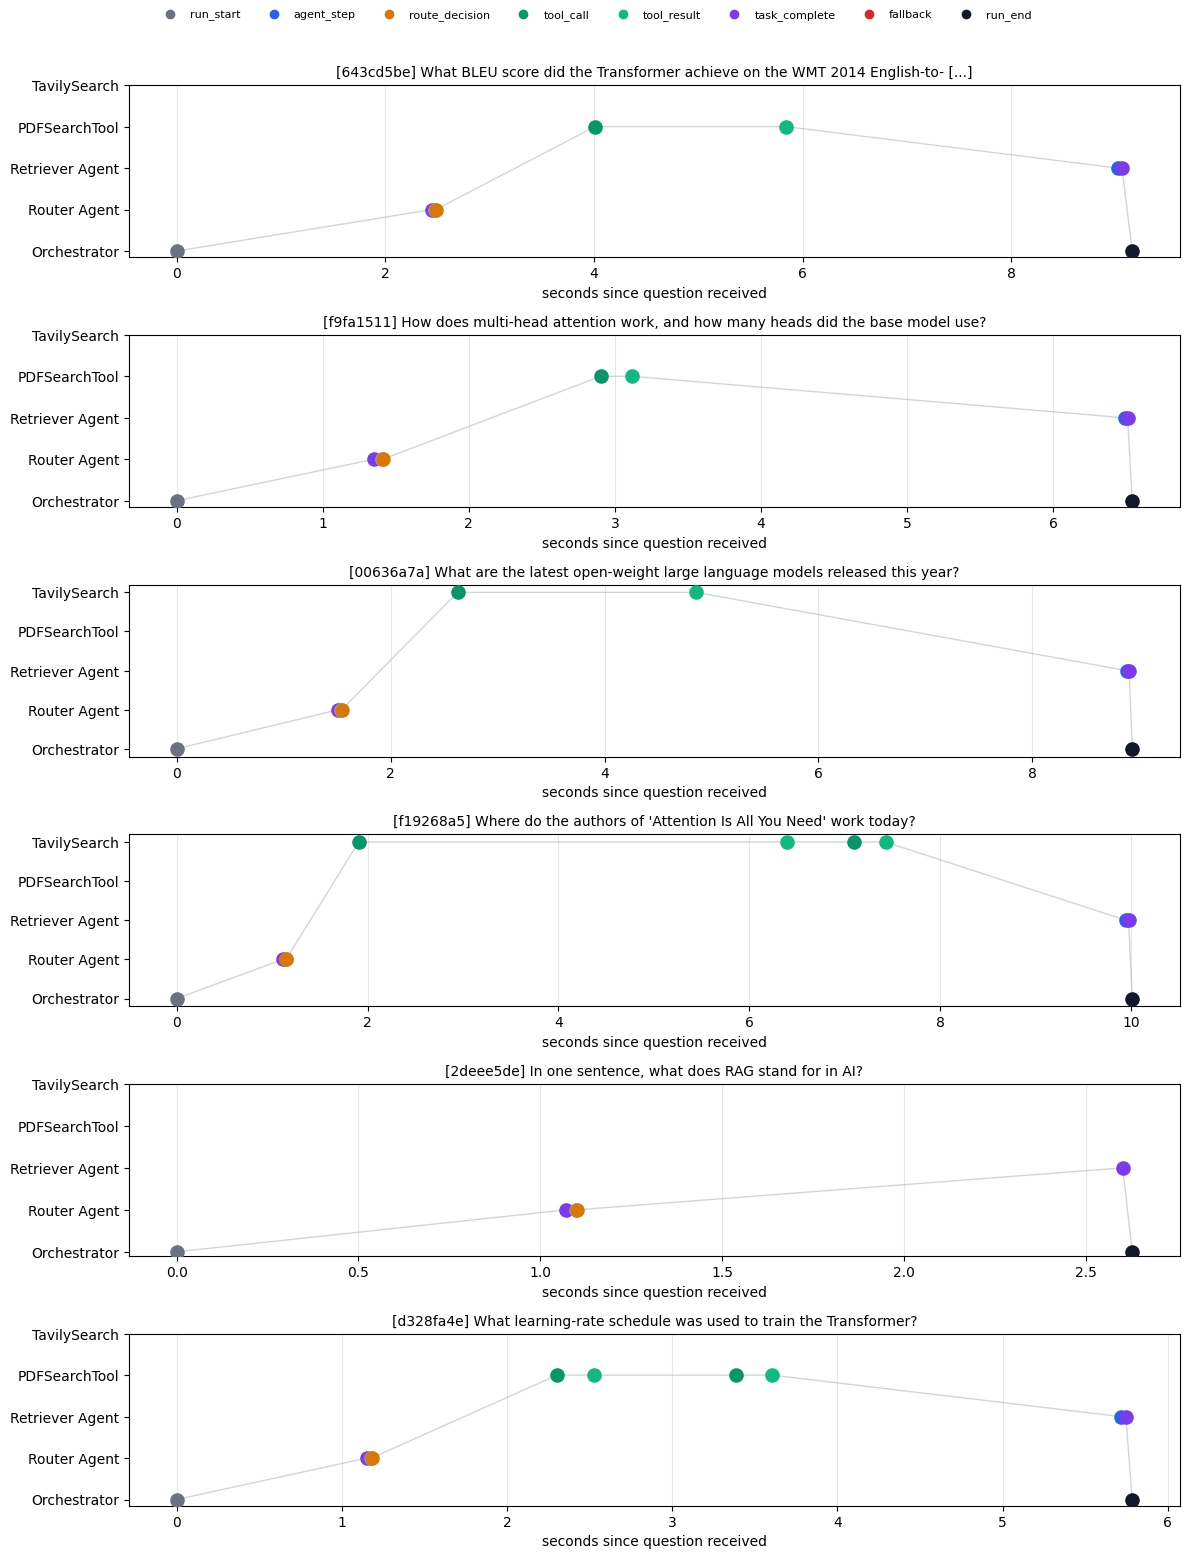

In [24]:
import matplotlib.pyplot as plt

LANES = ["Orchestrator", "Router Agent", "Retriever Agent", "PDFSearchTool", "TavilySearch"]
COLORS = {"run_start": "#6b7280", "agent_step": "#2563eb", "route_decision": "#d97706",
          "tool_call": "#059669", "tool_result": "#10b981", "task_complete": "#7c3aed",
          "fallback": "#dc2626", "run_end": "#111827"}


def plot_swimlane(run_id: str, ax=None):
    ev = [e for e in tracer.events if e["run_id"] == run_id]
    if not ev:
        return
    t0 = ev[0]["ts"]
    ax = ax or plt.gca()
    for e in ev:
        lane = e["agent"] if e["agent"] in LANES else "Orchestrator"
        y = LANES.index(lane)
        ax.scatter(e["ts"] - t0, y, s=90, color=COLORS.get(e["event"], "#9ca3af"), zorder=3)
    # connect consecutive events to show the hand-offs
    xs = [e["ts"] - t0 for e in ev]
    ys = [LANES.index(e["agent"]) if e["agent"] in LANES else 0 for e in ev]
    ax.plot(xs, ys, color="#d1d5db", lw=1, zorder=1)
    q = next(e["content"] for e in ev if e["event"] == "run_start")
    ax.set_yticks(range(len(LANES)), LANES)
    ax.set_xlabel("seconds since question received")
    ax.set_title(textwrap.shorten(f"[{run_id}] {q}", 90), fontsize=10)
    ax.grid(axis="x", alpha=.3)


runs = [r["run_id"] for r in rag.history]
fig, axes = plt.subplots(len(runs), 1, figsize=(12, 2.6 * len(runs)), sharex=False)
axes = [axes] if len(runs) == 1 else axes
for rid, ax in zip(runs, axes):
    plot_swimlane(rid, ax)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in COLORS.items()]
fig.legend(handles=handles, loc="upper center", ncol=len(COLORS), fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig("logs/swimlanes.png", dpi=120)
plt.show()

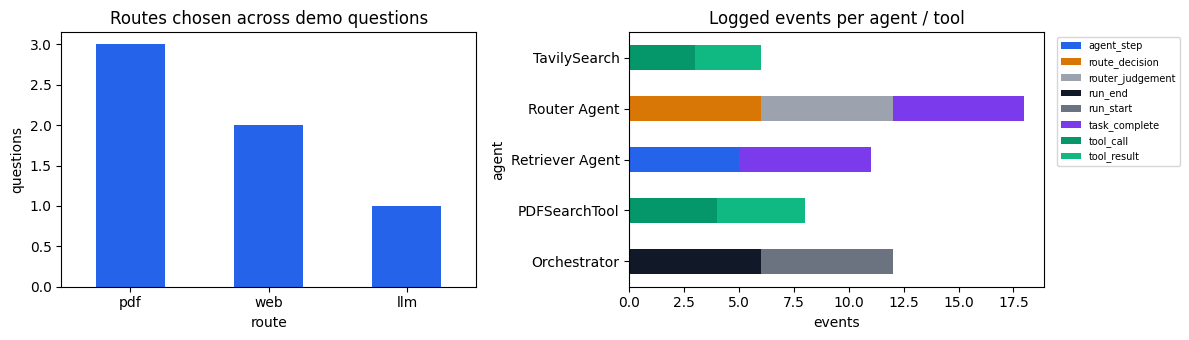

In [25]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
summary["route"].value_counts().plot.bar(ax=a1, color="#2563eb")
a1.set_title("Routes chosen across demo questions"); a1.set_ylabel("questions"); a1.tick_params(axis="x", rotation=0)

events.groupby(["agent", "event"]).size().unstack(fill_value=0).plot.barh(
    ax=a2, stacked=True, color=[COLORS.get(c, "#9ca3af") for c in events.groupby(["agent", "event"]).size().unstack().columns])
a2.set_title("Logged events per agent / tool"); a2.set_xlabel("events"); a2.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig("logs/summary_charts.png", dpi=120); plt.show()

In [26]:
# Persist the run summary and routing check next to the JSONL trace
summary.to_csv("logs/run_summary.csv", index=False)
route_check.to_csv("logs/routing_check.csv", index=False)
print("Saved: logs/trace.jsonl, logs/agentic_rag.log, logs/crew_router.log, logs/crew_retriever.log,"
      " logs/run_summary.csv, logs/routing_check.csv, logs/swimlanes.png, logs/summary_charts.png")

Saved: logs/trace.jsonl, logs/agentic_rag.log, logs/crew_router.log, logs/crew_retriever.log, logs/run_summary.csv, logs/routing_check.csv, logs/swimlanes.png, logs/summary_charts.png


## 9. Why CrewAI?

* **Role-first design.** CrewAI models agents as `role` + `goal` + `backstory`, which maps one-to-one onto the Router/Retriever responsibilities required here and keeps prompts readable.
* **Native tool ecosystem.** `PDFSearchTool` ships in `crewai_tools` (chunking + embedding + vector search in one line), and any LangChain tool such as `TavilySearchResults` can be wrapped as a `BaseTool`.
* **Structured outputs.** `output_pydantic` validates the router's decision, so the orchestrator branches on a typed object instead of parsing free text.
* **Built-in observability.** `step_callback`, `task_callback`, `verbose` and `output_log_file` give the hooks needed for the reasoning trace without extra infrastructure.
* **Alternatives considered.** *LangGraph* offers finer-grained graph control but needs more boilerplate for a two-agent pipeline; *AutoGen* is conversation-centric, which makes enforcing "use only the routed tool" harder. For a clear, auditable router → retriever pipeline, CrewAI is the simplest fit.

## 10. Conclusion

The system accepts a natural-language question, the **Router Agent** classifies it into `pdf` / `web` / `llm`, the orchestrator equips the **Retriever Agent** with exactly that tool, and the retriever returns a cited, source-grounded answer. Every step is logged to JSONL and visualised as swimlane timelines, giving full reasoning traceability.

**Key design lesson:** routing accuracy depends on the Router knowing *what each source contains*, not just that it exists. Giving it a table of contents extracted from the PDF keeps answers grounded in the paper even for topics the model already knows. A second lesson came from the logs: the LLM is better at narrow judgements ("is this time-sensitive?", "which section covers it?") than at applying ordered rules, so the rules now run in code. The routing check in 7.5 measures this. See `README.md` for architecture, responsibilities, and the challenges and trade-offs.